<a href="https://colab.research.google.com/github/moazamrehman/CodeAlpha_Task1_Web_Scraping/blob/main/CodeAlpha_Task1_Web_Scraping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install requests beautifulsoup4 pandas numpy matplotlib seaborn -q

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from urllib.parse import urljoin

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"

HEADERS = {
    "User-Agent": "Mozilla/5.0"
}

print("Website configured successfully!")
print(BASE_URL)

Website configured successfully!
https://books.toscrape.com/catalogue/page-{}.html


In [4]:
url = BASE_URL.format(1)

response = requests.get(
    url,
    headers=HEADERS,
    timeout=20
)

print("Status Code:", response.status_code)
print("Page Length:", len(response.text))

Status Code: 200
Page Length: 50469


In [10]:
soup = BeautifulSoup(
    response.text,
    "html.parser"
)

print(soup.title.text)

product = soup.select_one("article.product_pod")

print(product.prettify()[:3000])



    All products | Books to Scrape - Sandbox

<article class="product_pod">
 <div class="image_container">
  <a href="a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="../media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [11]:
product = soup.select_one("article.product_pod")

title = product.h3.a["title"]

price = product.select_one(".price_color").text.strip()

availability = product.select_one(
    ".availability"
).get_text(" ", strip=True)

rating_class = product.select_one(
    "p.star-rating"
)["class"]

print("Title:", title)
print("Price:", price)
print("Availability:", availability)
print("Rating Class:", rating_class)

Title: A Light in the Attic
Price: Â£51.77
Availability: In stock
Rating Class: ['star-rating', 'Three']


In [12]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

rating_word = None

for word in rating_map:
    if word in rating_class:
        rating_word = word
        break

rating = rating_map[rating_word]

print("Rating:", rating)

Rating: 3


In [13]:
records = []

for page_number in range(1, 51):

    url = BASE_URL.format(page_number)

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=20
    )

    response.raise_for_status()

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    products = soup.select(
        "article.product_pod"
    )

    for product in products:


        title = product.h3.a.get(
            "title",
            ""
        ).strip()


        price = product.select_one(
            ".price_color"
        ).get_text(strip=True)


        availability = product.select_one(
            ".availability"
        ).get_text(" ", strip=True)


        rating_element = product.select_one(
            "p.star-rating"
        )

        rating_classes = rating_element.get(
            "class",
            []
        )

        rating_word = None

        for word in rating_map:

            if word in rating_classes:

                rating_word = word

                break

        rating = rating_map.get(
            rating_word
        )

        image_element = product.select_one(
            "img"
        )

        if image_element:

            image_url = urljoin(
                url,
                image_element.get("src")
            )

        else:

            image_url = None


        records.append({

            "title": title,

            "price": price,

            "rating": rating,

            "availability": availability,

            "image_url": image_url,

            "source_page": page_number

        })

    print(
        f"Page {page_number}/50 completed"
    )

    time.sleep(0.2)

print("\nScraping completed!")
print("Total records:", len(records))

Page 1/50 completed
Page 2/50 completed
Page 3/50 completed
Page 4/50 completed
Page 5/50 completed
Page 6/50 completed
Page 7/50 completed
Page 8/50 completed
Page 9/50 completed
Page 10/50 completed
Page 11/50 completed
Page 12/50 completed
Page 13/50 completed
Page 14/50 completed
Page 15/50 completed
Page 16/50 completed
Page 17/50 completed
Page 18/50 completed
Page 19/50 completed
Page 20/50 completed
Page 21/50 completed
Page 22/50 completed
Page 23/50 completed
Page 24/50 completed
Page 25/50 completed
Page 26/50 completed
Page 27/50 completed
Page 28/50 completed
Page 29/50 completed
Page 30/50 completed
Page 31/50 completed
Page 32/50 completed
Page 33/50 completed
Page 34/50 completed
Page 35/50 completed
Page 36/50 completed
Page 37/50 completed
Page 38/50 completed
Page 39/50 completed
Page 40/50 completed
Page 41/50 completed
Page 42/50 completed
Page 43/50 completed
Page 44/50 completed
Page 45/50 completed
Page 46/50 completed
Page 47/50 completed
Page 48/50 completed
P

In [14]:
df = pd.DataFrame(records)

print("Dataset shape:")
print(df.shape)

display(df.head(10))

Dataset shape:
(1000, 6)


,title,price,rating,availability,image_url,source_page
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/media/cache/2c/da/2...,1
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/media/cache/26/0c/2...,1
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/media/cache/3e/ef/3...,1
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/media/cache/32/51/3...,1
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/media/cache/be/a5/b...,1
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/media/cache/68/33/6...,1
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/media/cache/92/27/9...,1
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/media/cache/3d/54/3...,1
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/media/cache/66/88/6...,1
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/media/cache/58/46/5...,1


In [15]:
print("Dataset Information:\n")

df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   title         1000 non-null   object
 1   price         1000 non-null   object
 2   rating        1000 non-null   int64 
 3   availability  1000 non-null   object
 4   image_url     1000 non-null   object
 5   source_page   1000 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 47.0+ KB


In [16]:
print("Missing values:\n")

print(df.isnull().sum())

Missing values:

title           0
price           0
rating          0
availability    0
image_url       0
source_page     0
dtype: int64


In [17]:
duplicate_count = df.duplicated().sum()

print(
    "Number of duplicate rows:",
    duplicate_count
)

Number of duplicate rows: 0


In [18]:
df["price"] = (
    df["price"]
    .str.replace("£", "", regex=False)
    .str.strip()
)

df["price"] = pd.to_numeric(
    df["price"],
    errors="coerce"
)

print(df["price"].dtype)

display(df.head())

float64


,title,price,rating,availability,image_url,source_page
0,A Light in the Attic,NaN,3,In stock,https://books.toscrape.com/media/cache/2c/da/2...,1
1,Tipping the Velvet,NaN,1,In stock,https://books.toscrape.com/media/cache/26/0c/2...,1
2,Soumission,NaN,1,In stock,https://books.toscrape.com/media/cache/3e/ef/3...,1
3,Sharp Objects,NaN,4,In stock,https://books.toscrape.com/media/cache/32/51/3...,1
4,Sapiens: A Brief History of Humankind,NaN,5,In stock,https://books.toscrape.com/media/cache/be/a5/b...,1


In [19]:
df["availability"] = (
    df["availability"]
    .str.replace(
        r"\s+",
        " ",
        regex=True
    )
    .str.strip()
)

display(
    df["availability"].value_counts()
)

,count
availability,
In stock,1000


In [20]:
before = len(df)

df = df.drop_duplicates(
    subset=["title"]
)

df = df.reset_index(
    drop=True
)

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 1000
Rows after: 999
Duplicates removed: 1


In [21]:
df["rating_label"] = df["rating"].map({

    1: "One Star",

    2: "Two Stars",

    3: "Three Stars",

    4: "Four Stars",

    5: "Five Stars"

})

display(
    df[
        [
            "title",
            "rating",
            "rating_label"
        ]
    ].head()
)

,title,rating,rating_label
0,A Light in the Attic,3,Three Stars
1,Tipping the Velvet,1,One Star
2,Soumission,1,One Star
3,Sharp Objects,4,Four Stars
4,Sapiens: A Brief History of Humankind,5,Five Stars


In [22]:
df["price_range"] = pd.cut(

    df["price"],

    bins=[
        0,
        20,
        30,
        40,
        50,
        np.inf
    ],

    labels=[
        "Under £20",
        "£20–£30",
        "£30–£40",
        "£40–£50",
        "Over £50"
    ],

    right=False
)

display(
    df[
        [
            "title",
            "price",
            "price_range"
        ]
    ].head(10)
)

,title,price,price_range
0,A Light in the Attic,NaN,NaN
1,Tipping the Velvet,NaN,NaN
2,Soumission,NaN,NaN
3,Sharp Objects,NaN,NaN
4,Sapiens: A Brief History of Humankind,NaN,NaN
5,The Requiem Red,NaN,NaN
6,The Dirty Little Secrets of Getting Your Dream...,NaN,NaN
7,The Coming Woman: A Novel Based on the Life of...,NaN,NaN
8,The Boys in the Boat: Nine Americans and Their...,NaN,NaN
9,The Black Maria,NaN,NaN


In [23]:
print("Final Dataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final Dataset Shape:
(999, 8)

Columns:
['title', 'price', 'rating', 'availability', 'image_url', 'source_page', 'rating_label', 'price_range']

Missing Values:
title             0
price           999
rating            0
availability      0
image_url         0
source_page       0
rating_label      0
price_range     999
dtype: int64

Duplicate Rows:
0


In [24]:
print("PRICE STATISTICS")

print(
    df["price"].describe()
)

PRICE STATISTICS
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: price, dtype: float64


In [25]:
average_price = df["price"].mean()

print(
    f"Average book price: £{average_price:.2f}"
)

Average book price: £nan


In [26]:
median_price = df["price"].median()

print(
    f"Median book price: £{median_price:.2f}"
)

Median book price: £nan


In [27]:
minimum_price = df["price"].min()

maximum_price = df["price"].max()

print(
    f"Minimum price: £{minimum_price:.2f}"
)

print(
    f"Maximum price: £{maximum_price:.2f}"
)

Minimum price: £nan
Maximum price: £nan


In [28]:
average_rating = df["rating"].mean()

print(
    f"Average rating: {average_rating:.2f}/5"
)

Average rating: 2.92/5


In [29]:
rating_counts = (
    df["rating"]
    .value_counts()
    .sort_index()
)

display(
    rating_counts.to_frame(
        "Number of Books"
    )
)

,Number of Books
rating,
1,226
2,196
3,203
4,179
5,195


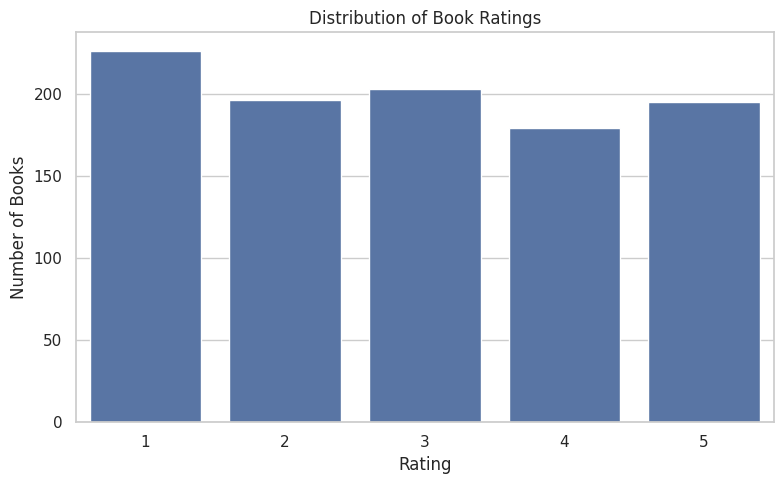

In [30]:
plt.figure(
    figsize=(8, 5)
)

sns.countplot(
    data=df,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title(
    "Distribution of Book Ratings"
)

plt.xlabel("Rating")

plt.ylabel(
    "Number of Books"
)

plt.tight_layout()

plt.show()

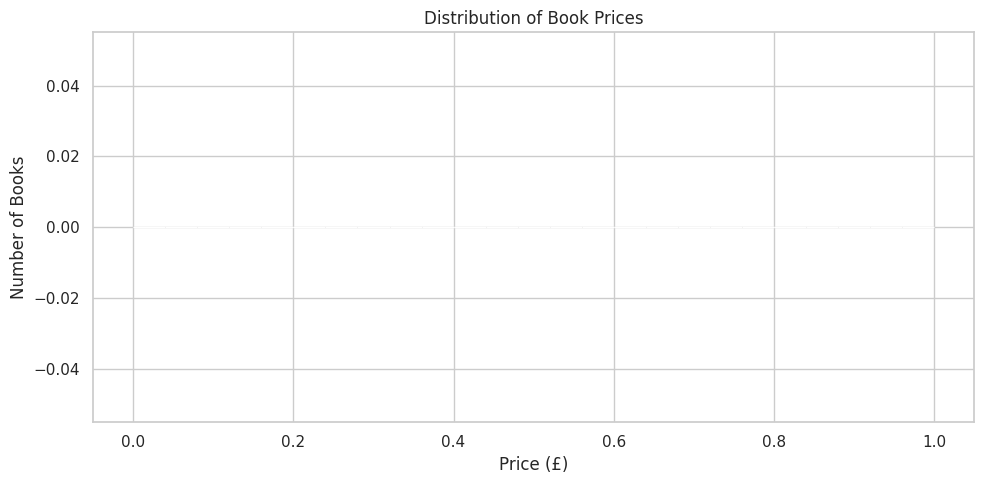

In [31]:
plt.figure(
    figsize=(10, 5)
)

sns.histplot(
    data=df,
    x="price",
    bins=25,
    kde=True
)

plt.title(
    "Distribution of Book Prices"
)

plt.xlabel(
    "Price (£)"
)

plt.ylabel(
    "Number of Books"
)

plt.tight_layout()

plt.show()

In [32]:
price_range_counts = (
    df["price_range"]
    .value_counts()
    .sort_index()
)

display(
    price_range_counts.to_frame(
        "Number of Books"
    )
)

,Number of Books
price_range,
Under £20,0
£20–£30,0
£30–£40,0
£40–£50,0
Over £50,0


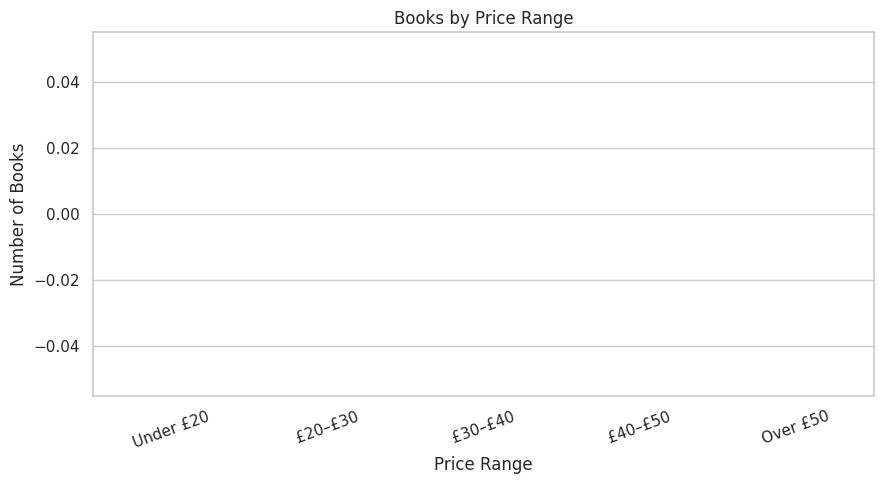

In [33]:
plt.figure(
    figsize=(9, 5)
)

sns.countplot(
    data=df,
    x="price_range",
    order=df["price_range"].cat.categories
)

plt.title(
    "Books by Price Range"
)

plt.xlabel(
    "Price Range"
)

plt.ylabel(
    "Number of Books"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.show()

In [34]:
top_10_expensive = (
    df.nlargest(
        10,
        "price"
    )
)

display(
    top_10_expensive[
        [
            "title",
            "price",
            "rating",
            "availability"
        ]
    ]
)

,title,price,rating,availability
0,A Light in the Attic,NaN,3,In stock
1,Tipping the Velvet,NaN,1,In stock
2,Soumission,NaN,1,In stock
3,Sharp Objects,NaN,4,In stock
4,Sapiens: A Brief History of Humankind,NaN,5,In stock
5,The Requiem Red,NaN,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,NaN,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,NaN,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,NaN,4,In stock
9,The Black Maria,NaN,1,In stock


In [35]:
top_10_cheapest = (
    df.nsmallest(
        10,
        "price"
    )
)

display(
    top_10_cheapest[
        [
            "title",
            "price",
            "rating",
            "availability"
        ]
    ]
)

,title,price,rating,availability
0,A Light in the Attic,NaN,3,In stock
1,Tipping the Velvet,NaN,1,In stock
2,Soumission,NaN,1,In stock
3,Sharp Objects,NaN,4,In stock
4,Sapiens: A Brief History of Humankind,NaN,5,In stock
5,The Requiem Red,NaN,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,NaN,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,NaN,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,NaN,4,In stock
9,The Black Maria,NaN,1,In stock


In [36]:
correlation = df[
    "price"
].corr(
    df["rating"]
)

print(
    f"Price-Rating Correlation: {correlation:.3f}"
)

Price-Rating Correlation: nan


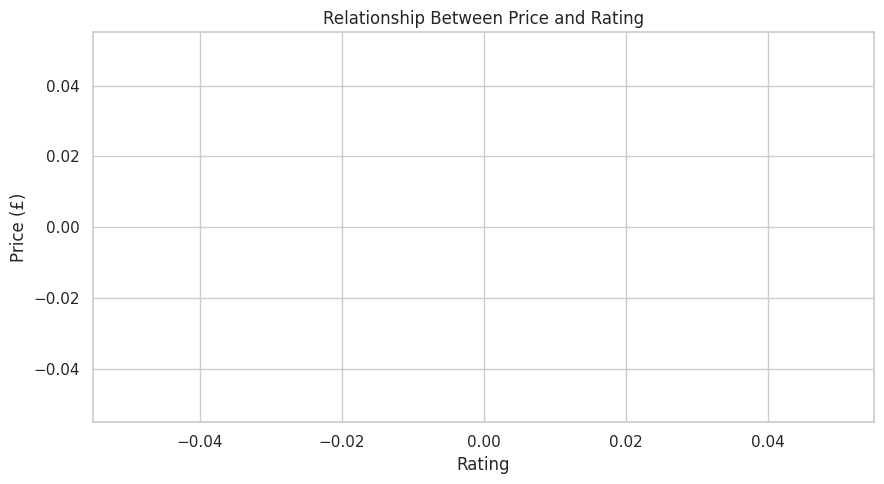

In [37]:
plt.figure(
    figsize=(9, 5)
)

sns.scatterplot(
    data=df,
    x="rating",
    y="price",
    alpha=0.7
)

plt.title(
    "Relationship Between Price and Rating"
)

plt.xlabel(
    "Rating"
)

plt.ylabel(
    "Price (£)"
)

plt.tight_layout()

plt.show()

In [38]:
average_price_rating = (
    df.groupby(
        "rating"
    )["price"]
    .mean()
    .reset_index()
)

display(
    average_price_rating
)

,rating,price
0,1,NaN
1,2,NaN
2,3,NaN
3,4,NaN
4,5,NaN


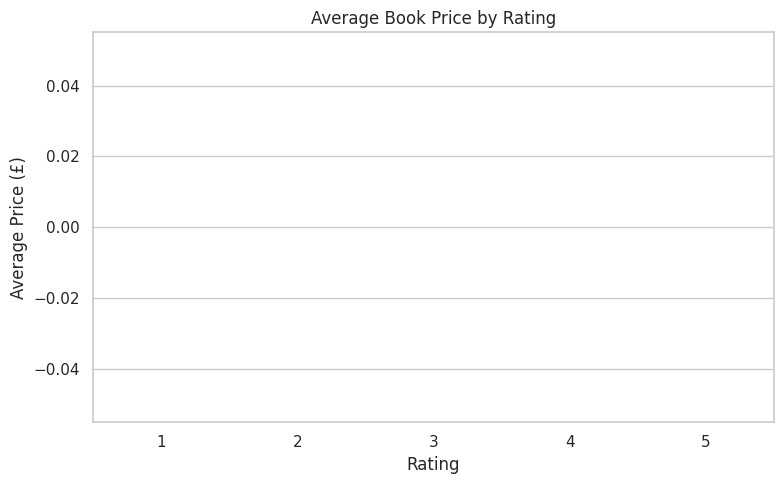

In [39]:
plt.figure(
    figsize=(8, 5)
)

sns.barplot(
    data=average_price_rating,
    x="rating",
    y="price"
)

plt.title(
    "Average Book Price by Rating"
)

plt.xlabel(
    "Rating"
)

plt.ylabel(
    "Average Price (£)"
)

plt.tight_layout()

plt.show()

In [40]:
rating_summary = (
    df.groupby("rating")
    .agg(

        Number_of_Books=(
            "title",
            "count"
        ),

        Average_Price=(
            "price",
            "mean"
        ),

        Minimum_Price=(
            "price",
            "min"
        ),

        Maximum_Price=(
            "price",
            "max"
        )

    )
    .reset_index()
)

display(
    rating_summary
)

,rating,Number_of_Books,Average_Price,Minimum_Price,Maximum_Price
0,1,226,NaN,NaN,NaN
1,2,196,NaN,NaN,NaN
2,3,203,NaN,NaN,NaN
3,4,179,NaN,NaN,NaN
4,5,195,NaN,NaN,NaN


In [41]:
price_summary = (
    df.groupby(
        "price_range",
        observed=True
    )
    .agg(

        Number_of_Books=(
            "title",
            "count"
        ),

        Average_Price=(
            "price",
            "mean"
        )

    )
    .reset_index()
)

display(
    price_summary
)

,price_range,Number_of_Books,Average_Price


In [44]:
print("FINAL DATASET")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

display(
    df.head(20)
)

FINAL DATASET
Rows: 999
Columns: 8


,title,price,rating,availability,image_url,source_page,rating_label,price_range
0,A Light in the Attic,NaN,3,In stock,https://books.toscrape.com/media/cache/2c/da/2...,1,Three Stars,NaN
1,Tipping the Velvet,NaN,1,In stock,https://books.toscrape.com/media/cache/26/0c/2...,1,One Star,NaN
2,Soumission,NaN,1,In stock,https://books.toscrape.com/media/cache/3e/ef/3...,1,One Star,NaN
3,Sharp Objects,NaN,4,In stock,https://books.toscrape.com/media/cache/32/51/3...,1,Four Stars,NaN
4,Sapiens: A Brief History of Humankind,NaN,5,In stock,https://books.toscrape.com/media/cache/be/a5/b...,1,Five Stars,NaN
5,The Requiem Red,NaN,1,In stock,https://books.toscrape.com/media/cache/68/33/6...,1,One Star,NaN
6,The Dirty Little Secrets of Getting Your Dream...,NaN,4,In stock,https://books.toscrape.com/media/cache/92/27/9...,1,Four Stars,NaN
7,The Coming Woman: A Novel Based on the Life of...,NaN,3,In stock,https://books.toscrape.com/media/cache/3d/54/3...,1,Three Stars,NaN
8,The Boys in the Boat: Nine Americans and Their...,NaN,4,In stock,https://books.toscrape.com/media/cache/66/88/6...,1,Four Stars,NaN
9,The Black Maria,NaN,1,In stock,https://books.toscrape.com/media/cache/58/46/5...,1,One Star,NaN
